Dataset Shape: (569, 30)

Diagnosis Count:
benign       357
malignant    212
Name: count, dtype: int64

 Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



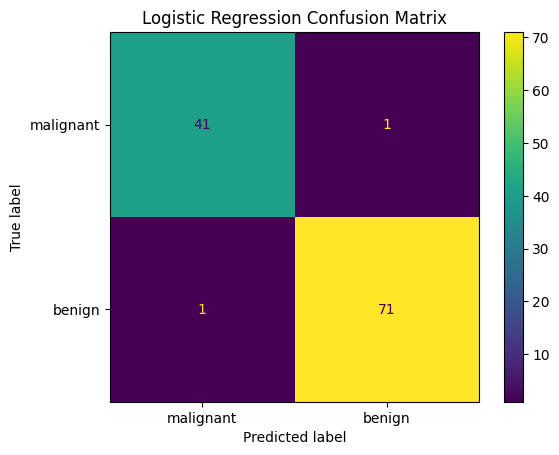


 Support Vector Machine
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



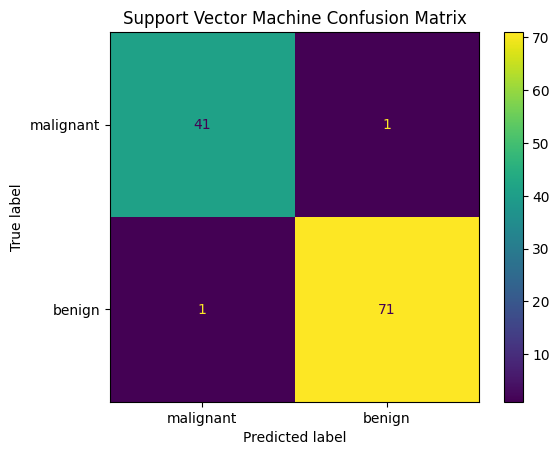


 Random Forest
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



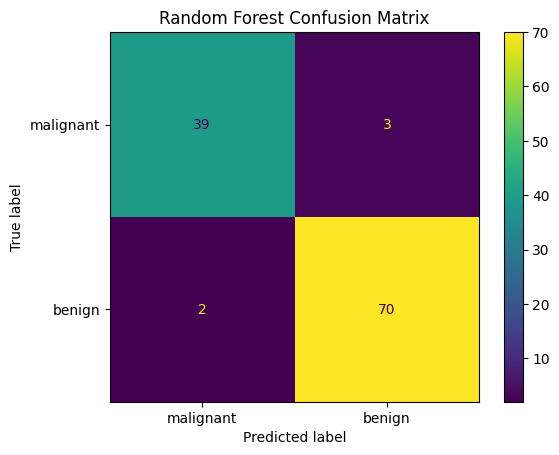


Model Comparison:
                 Model  Accuracy  Precision  Recall  F1 Score
   Logistic Regression    0.9825     0.9861  0.9861    0.9861
Support Vector Machine    0.9825     0.9861  0.9861    0.9861
         Random Forest    0.9561     0.9589  0.9722    0.9655

Example Prediction:
Predicted Diagnosis: malignant
Actual Diagnosis: malignant

Model execution completed successfully!
This project is for educational purposes only, not medical diagnosis.


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

print("Dataset Shape:", X.shape)
print("\nDiagnosis Count:")
print(pd.Series(data.target_names[y]).value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ]),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, pos_label=1)
    recall = recall_score(y_test, predictions, pos_label=1)
    f1 = f1_score(y_test, predictions, pos_label=1)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n", name)
    print(classification_report(
        y_test, predictions,
        target_names=data.target_names
    ))

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=data.target_names
    )
    display.plot()
    plt.title(name + " Confusion Matrix")
    plt.show()

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df.round(4).to_string(index=False))

results_df.to_csv("model_comparison.csv", index=False)

best_model = models["Logistic Regression"]

sample = X_test.iloc[[0]]
prediction = best_model.predict(sample)[0]

print("\nExample Prediction:")
print("Predicted Diagnosis:", data.target_names[prediction])
print("Actual Diagnosis:", data.target_names[y_test.iloc[0]])

print("\nModel execution completed successfully!")
print("This project is for educational purposes only, not medical diagnosis.")
